# Morse-Smale complex (MSC) graph barycenter

Compute a (partial) Fused Gromov–Wasserstein barycenter for a family of **Morse-Smale complexes** loaded from `./data/`, using **adjacency** (or shortest-path / heat-kernel) relation matrices.

This notebook mirrors the demo pipeline in `graph_barycenter_adjacency.ipynb`, but replaces synthetic graph generation with MSC files (`treeNodes_*.txt` / `treeEdges_*.txt`) via `lib/graph_reader.py`.

**Pipeline**
1. Select MSC snapshots (mesh indices) from `./data/`.
2. Load each complex as a `networkx.Graph` (`read_morse_graph_txt`), merging duplicate boundary nodes by `(x,y,z)`.
3. Verify connectivity of loaded graphs.
4. Subsample along Morse paths between critical points (critical nodes always kept).
5. Visualize processed graphs in the `(x, y)` plane from file coordinates.
6. Build shortest-path relation matrices (normalized) and node features `(x,y,z)` + normalized scalar + critical-point type for FGW.
7. Run partial FGW (PFGW) barycenter.
8. Reconstruct and visualize the barycenter graph.


In [23]:
# Imports (re-run this cell after editing files under lib/ — no kernel restart needed)
import importlib
import os
import re
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

import ot

import lib.graph_reader as graph_reader
import lib.gromov as gromov
import lib.gromov_barycenter as gromov_barycenter

importlib.reload(graph_reader)
importlib.reload(gromov)
importlib.reload(gromov_barycenter)

from lib.graph_reader import (
    read_morse_graph_txt,
    load_morse_graphs,
    prepare_graph_for_barycenter,
    summarize_graph_connectivity,
    merge_duplicate_nodes,
    sample_morse_graph,
    relation_matrix,
    compute_relation_rescale,
    apply_relation_scaling,
    reconstruct_msc_barycenter_mst_graph,
    node_height,
    msc_node_visual_type,
)
from ot.utils import dist
from lib.gromov import (
    partial_fused_gromov_ver1,
    partial_gromov_ver1,
    gromov_wasserstein,
    GW_dist,
    PGW_dist_with_penalty,
)
from lib.gromov_barycenter import pfgw_barycenters


In [190]:
# --- MSC data configuration ---
DATA_ROOT = Path("data")
# Default demo: VortexStreet MSC snapshots (edit mesh_ids / folder as needed)
# MSC_DIR = DATA_ROOT / "VortexStreet" / "MSC_1.0"
# mesh_ids = [148, 149, 150]  # three nearby time steps
MSC_DIR = DATA_ROOT / "synthetic" / "DESC-MC_1.0"
mesh_ids = [0, 1, 2]


_MSC_NODE_PATTERNS = (
    ("treeNodes_monoMesh_{mesh_id}.txt", "treeEdges_monoMesh_{mesh_id}.txt"),
    ("treeNodes_synthetic_noise_{mesh_id:02d}.txt", "treeEdges_synthetic_noise_{mesh_id:02d}.txt"),
)
_MSC_ID_PATTERNS = (
    re.compile(r"treeNodes_monoMesh_(\d+)\.txt$"),
    re.compile(r"treeNodes_synthetic_noise_(\d+)\.txt$"),
)


def msc_paths(mesh_id: int, msc_dir: Path = MSC_DIR):
    """Return (node_file, edge_file) for a mesh index.

    Supports monoMesh snapshots (treeNodes_monoMesh_*.txt) and synthetic
    noise datasets (treeNodes_synthetic_noise_*.txt).
    """
    for node_pat, edge_pat in _MSC_NODE_PATTERNS:
        node = msc_dir / node_pat.format(mesh_id=mesh_id)
        edge = msc_dir / edge_pat.format(mesh_id=mesh_id)
        if node.exists() and edge.exists():
            return str(node), str(edge)
    raise FileNotFoundError(f"Missing MSC files for mesh {mesh_id} in {msc_dir}")


def list_mesh_ids(msc_dir: Path = MSC_DIR):
    """Discover available mesh indices from treeNodes_*.txt in msc_dir."""
    ids = []
    seen = set()
    for p in sorted(msc_dir.glob("treeNodes_*.txt")):
        for pat in _MSC_ID_PATTERNS:
            m = pat.search(p.name)
            if m:
                mesh_id = int(m.group(1))
                if mesh_id not in seen:
                    seen.add(mesh_id)
                    ids.append(mesh_id)
                break
    return ids


print("MSC directory:", MSC_DIR.resolve())
print("Available meshes (count):", len(list_mesh_ids()))
print("Using mesh_ids:", mesh_ids)


MSC directory: C:\Users\mingz\desktop\MSCBarycenter\data\synthetic\DESC-MC_1.0
Available meshes (count): 5
Using mesh_ids: [0, 1, 2]


In [191]:
def load_msc_nx(mesh_id: int, msc_dir: Path = MSC_DIR):
    """Load one MSC as (nx.Graph, critical_node_ids)."""
    node_f, edge_f = msc_paths(mesh_id, msc_dir)
    G, critical_nodes = read_morse_graph_txt(node_f, edge_f)
    return G, critical_nodes


# prepare_graph_for_barycenter: path sampling along ascending/descending edges
# (see lib/graph_reader.sample_morse_graph); critical nodes are always kept.


# Load raw MSC graphs
raw_graphs = []
critical_lists = []
for mid in mesh_ids:
    G, crit = load_msc_nx(mid)
    raw_graphs.append(G)
    critical_lists.append(crit)
    print(
        f"mesh {mid}: nodes={G.number_of_nodes()}, edges={G.number_of_edges()}, "
        f"critical={len(crit)}"
    )

# Connectivity check on loaded (unsampled) graphs
print("\n--- Loaded graph connectivity ---")
raw_connectivity = []
for mid, G, crit in zip(mesh_ids, raw_graphs, critical_lists):
    info = summarize_graph_connectivity(G, label=f"loaded mesh {mid}", critical_nodes=crit)
    raw_connectivity.append(info)


mesh 0: nodes=4744, edges=4752, critical=16
mesh 1: nodes=5155, edges=5168, critical=51
mesh 2: nodes=5133, edges=5146, critical=49

--- Loaded graph connectivity ---
[loaded mesh 0] CONNECTED
  nodes=4744, edges=4752, largest component=4744
  critical nodes (id list): 16 in graph, 16 in largest component
  critical nodes (separatrixType=0): 16
[loaded mesh 1] CONNECTED
  nodes=5155, edges=5168, largest component=5155
  critical nodes (id list): 51 in graph, 51 in largest component
  critical nodes (separatrixType=0): 51
[loaded mesh 2] CONNECTED
  nodes=5133, edges=5146, largest component=5133
  critical nodes (id list): 49 in graph, 49 in largest component
  critical nodes (separatrixType=0): 49


In [192]:
# Graphs used for barycenter (path subsampling between critical points)
SAMPLE_RATE = 0.1       # lower rate -> more nodes along paths (on largest component)
SAMPLE_MODE = "geo"     # 'step' | 'geo'
# 'largest' keeps one connected piece (required for connected subsample); 'full' keeps all components
SAMPLE_COMPONENT = "largest"

Gs = []
critical_lists_sampled = []
for G, crit in zip(raw_graphs, critical_lists):
    H, crit_h = prepare_graph_for_barycenter(
        G,
        critical_nodes=crit,
        rate=SAMPLE_RATE,
        mode=SAMPLE_MODE,
        component=SAMPLE_COMPONENT,
    )
    Gs.append(H)
    critical_lists_sampled.append(crit_h)

print("\n--- Subsampled graph connectivity ---")
for i, G in enumerate(Gs):
    summarize_graph_connectivity(
        G,
        label=f"subsampled mesh {mesh_ids[i]}",
        critical_nodes=critical_lists_sampled[i],
    )



--- Subsampled graph connectivity ---
[subsampled mesh 0] CONNECTED
  nodes=96, edges=104, largest component=96
  critical nodes (id list): 16 in graph, 16 in largest component
  critical nodes (separatrixType=0): 16
[subsampled mesh 1] CONNECTED
  nodes=131, edges=144, largest component=131
  critical nodes (id list): 51 in graph, 51 in largest component
  critical nodes (separatrixType=0): 51
[subsampled mesh 2] CONNECTED
  nodes=131, edges=144, largest component=131
  critical nodes (id list): 49 in graph, 49 in largest component
  critical nodes (separatrixType=0): 49


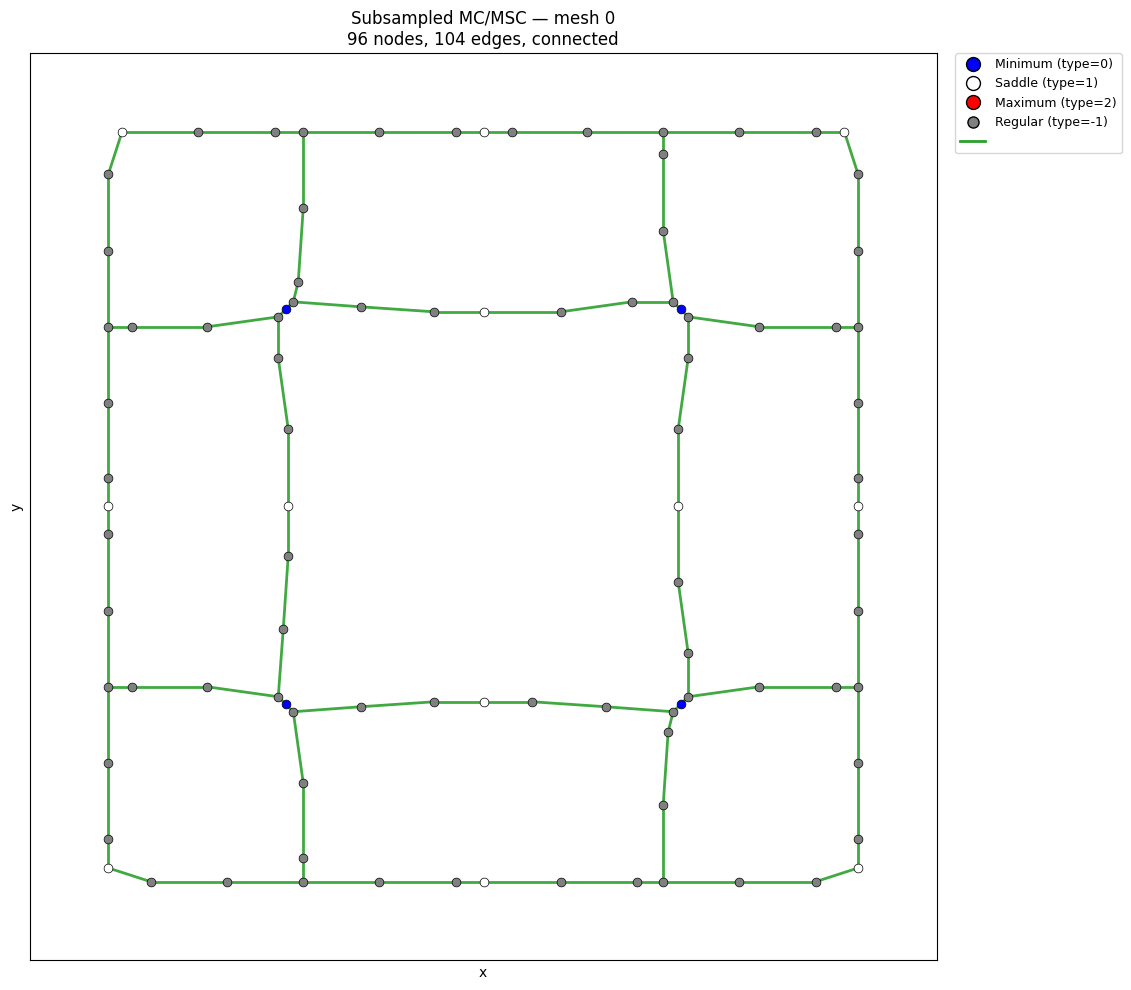

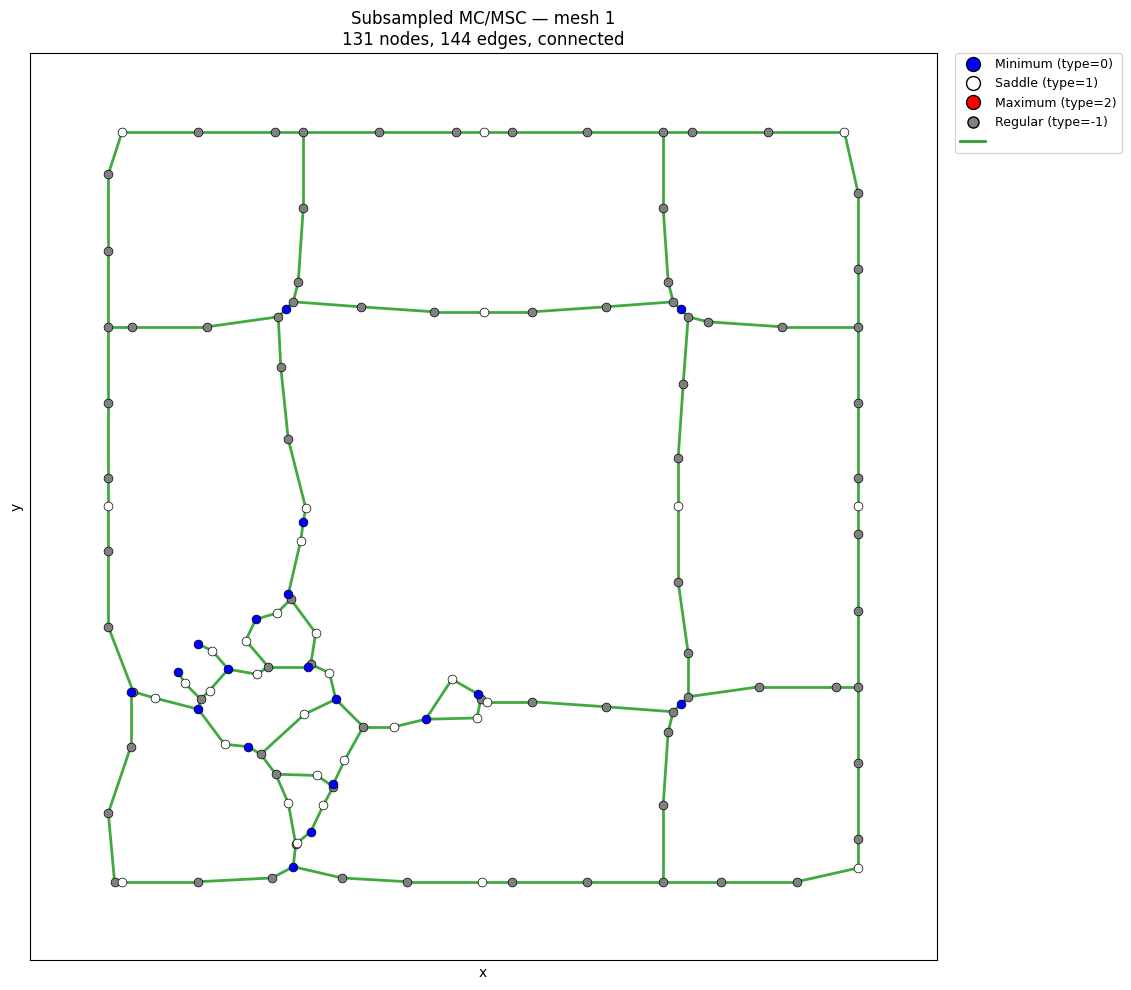

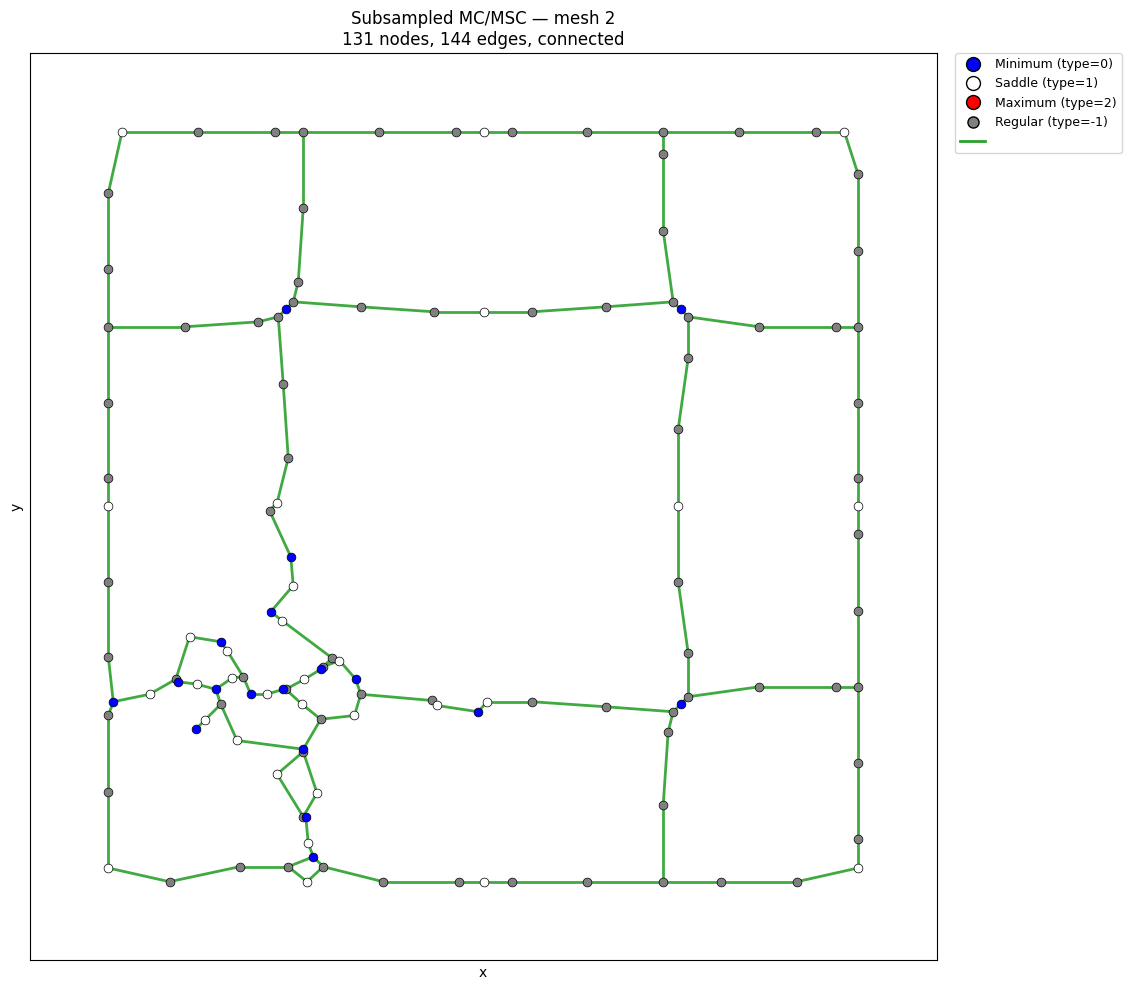

In [193]:
# Visualize processed (subsampled) MSC graphs in the (x, y) plane from file coordinates

from matplotlib.lines import Line2D

from lib.graph_reader import draw_msc_nodes


def msc_xy_positions(G):
    """Layout from node attributes x, y (as stored in the MSC files)."""
    return {n: np.array([G.nodes[n]["x"], G.nodes[n]["y"]], dtype=float) for n in G.nodes()}


def draw_processed_msc_graphs(
    graphs,
    mesh_ids=mesh_ids,
    figsize=(16.0, 10.0),
    critical_size=40,
    regular_size=40,
    edge_width=2.0,
    show_labels=False,
):
    """
    One figure per graph (no subplots). Node IDs are not drawn by default.

    Node colors (from node ``type``):
      - blue  : minimum   (type == 0)
      - white : saddle    (type == 1)
      - red   : maximum   (type == 2)
      - gray  : regular   (type == -1)

    Edge colors (from file column edge type):
      - green : ascending manifold  (type == 0)
      - orange: descending manifold (type == 1)
    """
    legend_handles = [
        Line2D([0], [0], marker="o", color="w", markerfacecolor="blue", markeredgecolor="black", markersize=10, label="Minimum (type=0)"),
        Line2D([0], [0], marker="o", color="w", markerfacecolor="white", markeredgecolor="black", markersize=10, label="Saddle (type=1)"),
        Line2D([0], [0], marker="o", color="w", markerfacecolor="red", markeredgecolor="black", markersize=10, label="Maximum (type=2)"),
        Line2D([0], [0], marker="o", color="w", markerfacecolor="gray", markeredgecolor="black", markersize=8, label="Regular (type=-1)"),
        Line2D([0], [0], color="#2ca02c", linewidth=2),
        # Line2D([0], [0], color="#2ca02c", linewidth=2, label="Ascending edge (type=0)"),
        # Line2D([0], [0], color="#ff7f0e", linewidth=2, label="Descending edge (type=1)"),
    ]

    for i, G in enumerate(graphs):
        fig, ax = plt.subplots(figsize=figsize)
        pos = msc_xy_positions(G)

        edges0 = [(u, v) for u, v, d in G.edges(data=True)] #  if int(d.get("type", 0)) == 0]
        # edges1 = [(u, v) for u, v, d in G.edges(data=True) if int(d.get("type", 0)) == 1]

        if edges0:
            nx.draw_networkx_edges(G, pos, edgelist=edges0, edge_color="#2ca02c", width=edge_width, alpha=0.9, ax=ax)
        # if edges1:
        #     nx.draw_networkx_edges(G, pos, edgelist=edges1, edge_color="#ff7f0e", width=edge_width, alpha=0.9, ax=ax)
        draw_msc_nodes(
            G,
            pos,
            ax,
            regular_size=regular_size,
            critical_size=critical_size,
        )

        if show_labels:
            nx.draw_networkx_labels(G, pos, font_size=9, ax=ax)

        conn = "connected" if nx.is_connected(G) else f"{nx.number_connected_components(G)} components"
        mid = mesh_ids[i] if mesh_ids is not None else i
        ax.set_title(f"Subsampled MC/MSC — mesh {mid}\n{G.number_of_nodes()} nodes, {G.number_of_edges()} edges, {conn}")
        ax.set_xlabel("x")
        ax.set_ylabel("y")
        ax.set_aspect("equal", adjustable="box")
        ax.legend(
            handles=legend_handles,
            loc="upper left",
            bbox_to_anchor=(1.02, 1.0),
            borderaxespad=0.0,
            fontsize=9,
        )
        fig.tight_layout(rect=[0, 0, 0.82, 1])
        plt.show()


draw_processed_msc_graphs(Gs)

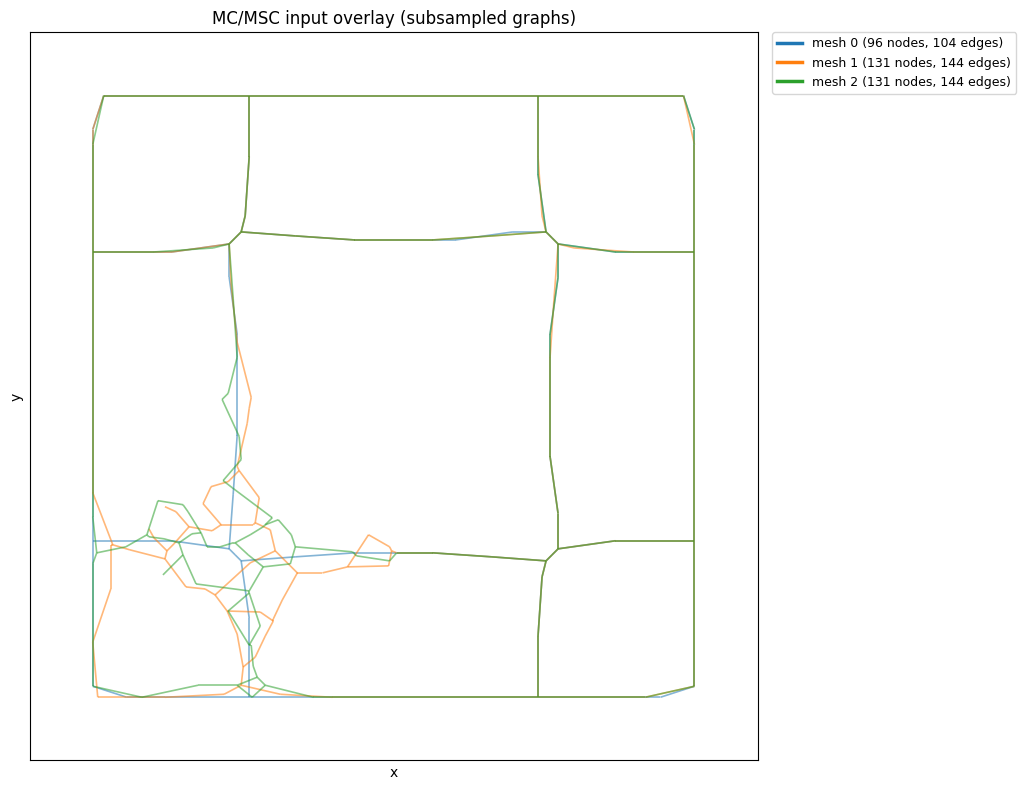

In [194]:
# Overlay all input MSC graphs in one (x, y) view — one edge color per mesh
# Requires cell above (msc_xy_positions). Re-run that cell if needed.

from matplotlib.lines import Line2D

from lib.graph_reader import draw_msc_nodes


def draw_msc_graphs_overlay(
    graphs,
    mesh_ids=None,
    edge_colors=None,
    figsize=(16.0, 8.0),
    edge_width=1.2,
    edge_alpha=0.55,
    show_nodes=False,
    node_size=8,
    node_color="#333333",
    node_alpha=0.25,
):
    """
    Draw subsampled MSC graphs on top of each other for shape comparison.

    Each input graph uses a single edge color (ascending + descending edges alike).
    """
    if mesh_ids is None:
        mesh_ids = list(range(len(graphs)))
    if edge_colors is None:
        palette = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b"]
        edge_colors = [palette[i % len(palette)] for i in range(len(graphs))]

    fig, ax = plt.subplots(figsize=figsize)
    legend_handles = []

    for i, G in enumerate(graphs):
        pos = msc_xy_positions(G)
        color = edge_colors[i]
        mid = mesh_ids[i] if i < len(mesh_ids) else i

        edgelist = list(G.edges())
        if edgelist:
            nx.draw_networkx_edges(
                G,
                pos,
                edgelist=edgelist,
                edge_color=color,
                width=edge_width,
                alpha=edge_alpha,
                ax=ax,
            )

        if show_nodes and G.number_of_nodes() > 0:
            draw_msc_nodes(
                G,
                pos,
                ax,
                regular_size=node_size,
                critical_size=node_size,
            )

        legend_handles.append(
            Line2D(
                [0],
                [0],
                color=color,
                linewidth=2.5,
                label=f"mesh {mid} ({G.number_of_nodes()} nodes, {G.number_of_edges()} edges)",
            )
        )

    ax.set_title("MC/MSC input overlay (subsampled graphs)")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_aspect("equal", adjustable="box")
    ax.legend(
        handles=legend_handles,
        loc="upper left",
        bbox_to_anchor=(1.02, 1.0),
        borderaxespad=0.0,
        fontsize=9,
    )
    fig.tight_layout(rect=[0, 0, 0.78, 1])
    plt.show()


draw_msc_graphs_overlay(Gs, mesh_ids=mesh_ids)

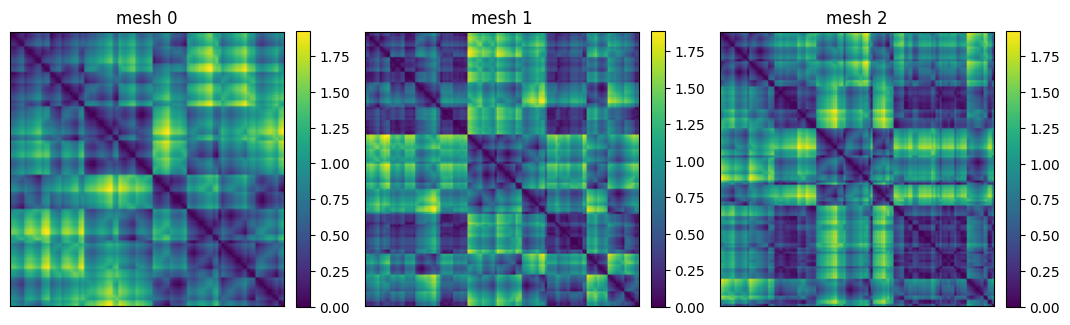

In [195]:
# Relation matrices (lib/graph_reader.relation_matrix — reload after edits)
import importlib
import lib.graph_reader as graph_reader

importlib.reload(graph_reader)
from lib.graph_reader import relation_matrix


def show_relation_matrices(graphs, kind="adjacency", cmap="viridis", sp_weighted=True):
    n = len(graphs)
    fig, axes = plt.subplots(1, n, figsize=(3.6 * n, 3.2), squeeze=False)
    for i, G in enumerate(graphs):
        C, _ = relation_matrix(G, kind=kind, sp_weighted=sp_weighted)
        ax = axes[0, i]
        im = ax.imshow(C, cmap=cmap)
        ax.set_title(f"mesh {mesh_ids[i]}")
        ax.set_xticks([])
        ax.set_yticks([])
        ax.grid(False)
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    plt.tight_layout()
    plt.show()


show_relation_matrices(Gs, kind="shortestpath", sp_weighted=True)


In [290]:
# Barycenter computation (partial FGW / PFGW)
# Shortest-path structure uses summed 3D Euclidean edge lengths (sp_weighted=True).
# Rescale: C_scaled = C_raw / max_global_shortest_path (same as contour-tree FGW).
from lib.gromov import PFGW_dist_with_penalty
def _pfgw_total_cost(C_tmp, X_tmp, log_tmp, debug=False):
    total = 0.0
    for s in range(len(Cs)):
        M_s = dist(X_tmp, Ys[s])
        d, penalty = PFGW_dist_with_penalty(M_s, C_tmp, Cs[s], log_tmp["T"][s], p, ps[s], Lambda_list[s], alpha=alpha_fgw)
        print("d, penalty:", d, penalty)
        total += lambdas[s] * (d + penalty)
    return float(total)

balanced_distribution = True
relation_kind = "shortestpath"
laplacian_base = "adjacency"
laplacian_normalization = "none"
tau = 1.0
sp_weighted = True  # sum 3D Euclidean edge lengths (MSC edges store Euclidean dist)
sp_affinity = "exp"
sp_sigma = None
relation_rescale = 1.0
relation_offset = 0.0

relation_rescale, relation_offset, rescale_diag = compute_relation_rescale(
    Gs, relation_kind, sp_weighted=sp_weighted
)
print("Rescale diagnostics:", rescale_diag)
print("relation_rescale:", relation_rescale)

use_partial = True
idx_list = list(range(len(Gs)))
n_graphs = len(idx_list)
N_min = max(Gs[idx].number_of_nodes() for idx in idx_list)
N_center = N_min
lambdas = np.ones(n_graphs, dtype=float) / n_graphs
max_iter = 200
bary_tol = 1e-6
random_state = 0
lambda_penalty = 0.05
alpha_fgw = 0.5
gw_restarts = 10
gw_seed_start = 0

print("lambda_penalty:", lambda_penalty, "alpha_fgw:", alpha_fgw)

# Node features for FGW: normalized (x, y, z) + normalized scalar + critical-point type
MSC_TYPE_ORDER = [0, 1, 2, -1]  # minimum, saddle, maximum, regular
type_to_idx = {t: i for i, t in enumerate(MSC_TYPE_ORDER)}
n_types = len(MSC_TYPE_ORDER)
type_scale = 0.4 / np.sqrt(2)   # type mismatch cost = 2 * (type_scale ** 2)

all_x, all_y, all_z = [], [], []
all_scalars = []
for idx in idx_list:
    G = Gs[idx]
    for n in G.nodes():
        all_x.append(G.nodes[n]["x"])
        all_y.append(G.nodes[n]["y"])
        all_z.append(G.nodes[n]["z"])
        all_scalars.append(node_height(G, n))

min_x, max_x = min(all_x), max(all_x)
min_y, max_y = min(all_y), max(all_y)
min_z, max_z = min(all_z), max(all_z)
domain_size = np.sqrt((max_x - min_x) ** 2 + (max_y - min_y) ** 2 + (max_z - min_z) ** 2)
domain_size = domain_size if domain_size > 0 else 1.0
min_scalar, max_scalar = min(all_scalars), max(all_scalars)
scalar_range = max_scalar - min_scalar
scalar_range = scalar_range if scalar_range > 0 else 1.0

Ys = []
Cs = []
nodes_list = []
for idx in idx_list:
    G = Gs[idx]
    C_idx, nodes_idx = relation_matrix(
        G,
        kind=relation_kind,
        laplacian_base=laplacian_base,
        laplacian_normalization=laplacian_normalization,
        tau=tau,
        sp_weighted=sp_weighted,
        sp_affinity=sp_affinity,
        sp_sigma=sp_sigma,
    )
    if relation_kind == "shortestpath":
        C_idx = apply_relation_scaling(
            C_idx, relation_kind, relation_rescale, relation_offset
        )
    Cs.append(C_idx)
    nodes_list.append(nodes_idx)

    coords = np.array(
        [
            [
                (G.nodes[n]["x"] - min_x) / domain_size,
                (G.nodes[n]["y"] - min_y) / domain_size,
                (G.nodes[n]["z"] - min_z) / domain_size,
            ]
            for n in nodes_idx
        ],
        dtype=float,
    )
    scalars = np.array(
        [(node_height(G, n) - min_scalar) / scalar_range for n in nodes_idx],
        dtype=float,
    ).reshape(-1, 1)
    onehot = np.zeros((len(nodes_idx), n_types), dtype=float)
    for i, n in enumerate(nodes_idx):
        onehot[i, type_to_idx[msc_node_visual_type(G.nodes[n])]] = type_scale
    Ys.append(np.column_stack([coords, scalars, onehot]))
    
    # Ys.append(np.column_stack([coords]))

ps = [np.ones(C.shape[0]) for C in Cs]
p = np.ones(N_center)
if balanced_distribution:
    ps = [pe / pe.sum() for pe in ps]
    p = p / p.sum()

if use_partial:
    Lambda_list = None if lambda_penalty is None else [lambda_penalty] * n_graphs
    C_center, X_center, log = pfgw_barycenters(
        N=N_center,
        Ys=Ys,
        Cs=Cs,
        ps=ps,
        p=p,
        Lambda_list=Lambda_list,
        lambdas=lambdas,
        alpha=alpha_fgw,
        max_iter=max_iter,
        tol=bary_tol,
        log=True,
        init_C=Cs[2],
        init_X=Ys[2],
        random_state=random_state,
        gw_restarts=gw_restarts,
        gw_seed_start=gw_seed_start,
        debug=True,
    )
else:
    Lambda_list = [1000] * n_graphs
    C_center, X_center, log = pfgw_barycenters(
        N=N_center,
        Ys=Ys,
        Cs=Cs,
        ps=ps,
        p=p,
        Lambda_list=Lambda_list,
        lambdas=lambdas,
        alpha=alpha_fgw,
        max_iter=max_iter,
        tol=bary_tol,
        log=True,
        random_state=random_state,
        gw_restarts=gw_restarts,
        gw_seed_start=gw_seed_start,
        debug=True,
    )

print("relation_kind:", relation_kind)
print("Barycenter matrix shape:", C_center.shape)
print("Barycenter feature shape:", X_center.shape)
if relation_kind == "shortestpath":
    C_center = np.nan_to_num(C_center, nan=np.inf, posinf=np.inf)
elif relation_kind == "adjacency":
    C_center = np.nan_to_num(C_center, nan=0.0)
    
print("PFGW Cost:", _pfgw_total_cost(C_center, X_center, log))


Rescale diagnostics: {'relation_kind': 'shortestpath', 'sp_weighted': True, 'max_dist_per_graph': [1.9269296199213737, 1.889426836202855, 1.9285887470758833], 'max_dist_global': 1.9285887470758833}
relation_rescale: 0.5185138622820418
lambda_penalty: 0.05 alpha_fgw: 0.5
pfgw barycenter starts...
iter 0 err 2.6403214782233384
iter 1 err 0.5244050915192101
iter 2 err 0.03425824775483037
iter 3 err 0.0
relation_kind: shortestpath
Barycenter matrix shape: (131, 131)
Barycenter feature shape: (131, 8)
d, penalty: 0.0009852938158000106 0.04267140518471693
d, penalty: 0.0010960479386675156 0.004527708175513667
d, penalty: 0.0005697047850300934 2.2204460492503132e-17
PFGW Cost: 0.016616719966576078


In [291]:
print(log['T'][0])

[[0.00000000e+00 0.00000000e+00 0.00000000e+00 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 ...
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 [1.04166667e-17 1.04166667e-17 1.04166667e-17 ... 1.04166667e-17
  1.04166667e-17 1.04166667e-17]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]]


In [292]:
print(X_center)

[[1.29633886e-02 7.07106781e-01 0.00000000e+00 ... 2.82842712e-01
  0.00000000e+00 0.00000000e+00]
 [8.48528137e-02 7.07106781e-01 0.00000000e+00 ... 0.00000000e+00
  0.00000000e+00 2.82842712e-01]
 [1.56742239e-01 7.07106781e-01 0.00000000e+00 ... 0.00000000e+00
  0.00000000e+00 2.82842712e-01]
 ...
 [4.29174532e-02 1.84633359e-01 0.00000000e+00 ... 0.00000000e+00
  0.00000000e+00 2.82842712e-01]
 [4.12480134e-02 1.75008928e-01 0.00000000e+00 ... 2.82842712e-01
  0.00000000e+00 1.54384981e-14]
 [1.63813071e-01 3.58267436e-01 0.00000000e+00 ... 0.00000000e+00
  0.00000000e+00 2.82842712e-01]]


Barycenter graph: 131 nodes, 130 edges (MST)
unscaled weight - euclidean (all edges): [ 6.94379524e-05 -1.38777878e-17 -2.08166817e-17  1.38777878e-17
  1.38777878e-17  0.00000000e+00 -4.85722573e-17  1.17961196e-16
 -9.71445147e-17  1.26895129e-03  4.65926856e-03  2.87737388e-03
  4.22220000e-02  5.25752156e-05  1.28654150e-02  2.04970253e-03
  3.70804752e-03 -2.22044605e-16  6.93889390e-17 -1.38777878e-17
 -9.71445147e-17  1.58595916e-04  6.50661882e-05  4.62821947e-02
  4.26792116e-03  1.38777878e-17  1.17961196e-16 -8.32667268e-17
  1.03987437e-02  5.90802583e-02  4.30498372e-03  1.04987748e-02
  1.99849727e-03  4.60201811e-03  5.93418998e-03  6.46410903e-02
  3.13839411e-03  3.27843196e-02  1.77104624e-02  1.12418844e-03
  9.95432495e-03  3.38334981e-03  4.38818445e-03  4.86884823e-03
  1.69908987e-02  1.38374326e-02  3.77660294e-02  2.70508468e-02
  2.02588889e-02  1.10311891e-03  2.18825660e-02 -2.37361607e-02
  1.05365852e-02  6.43668592e-03  1.01077946e-03  1.41997907e-02
  5.

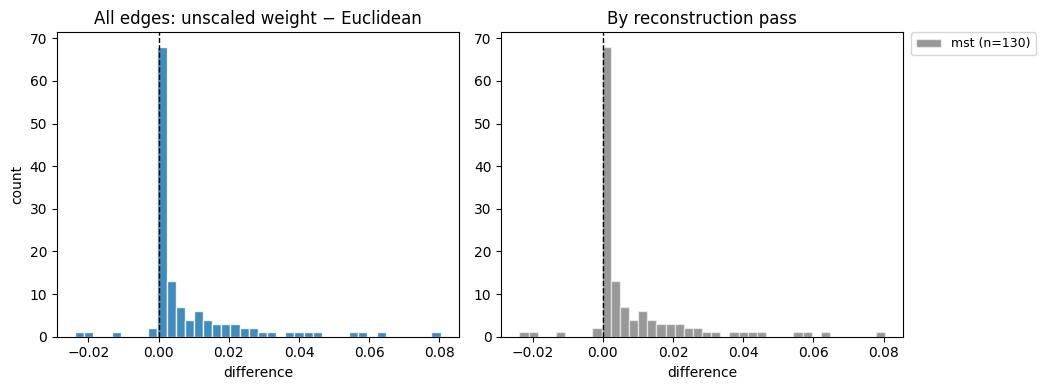

relation unscale: kind=shortestpath, sp_weighted=True, rescale=0.518514, offset=0
unscaled weight − euclidean: n=130, min=-0.0237362, max=0.0802952, mean=0.00746364, std=0.0147888, below_eucl=6
Top |difference| edges:
  (96, 97) pass=mst weight_scaled=0.049946 weight_raw=0.0963253 eucl=0.0160301 diff=0.0802952
  (31, 109) pass=mst weight_scaled=0.0493711 weight_raw=0.0952166 eucl=0.0305755 diff=0.0646411
  (26, 27) pass=mst weight_scaled=0.0417537 weight_raw=0.0805257 eucl=0.0214454 diff=0.0590803
  (45, 83) pass=mst weight_scaled=0.032695 weight_raw=0.0630552 eucl=0.00671884 diff=0.0563364
  (22, 130) pass=mst weight_scaled=0.0303156 weight_raw=0.0584664 eucl=0.0121842 diff=0.0462822


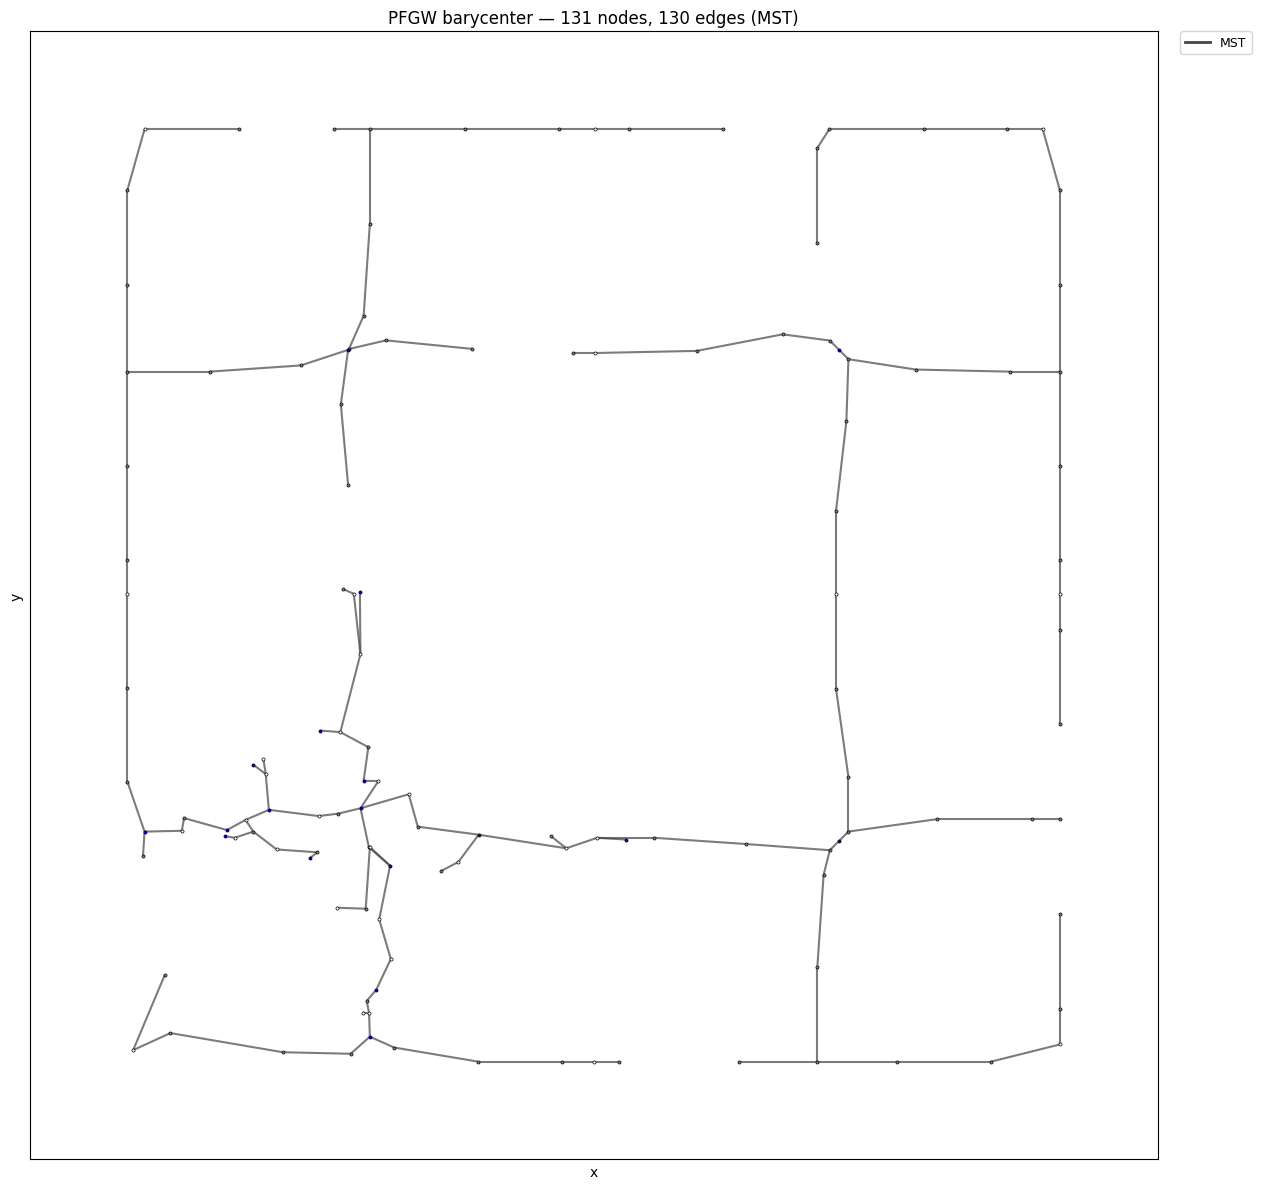

In [293]:
# Reconstruct and draw FGW barycenter graph
# Reconstruct barycenter graph as a Kruskal MST over FGW relation weights.

import importlib
import lib.graph_reader as graph_reader

importlib.reload(graph_reader)
from lib.graph_reader import (
    reconstruct_msc_barycenter_mst_graph,
    msc_barycenter_weight_euclidean_differences,
    msc_barycenter_weight_euclidean_debug,
    plot_msc_barycenter_weight_euclidean_debug,
    draw_msc_nodes,
)


def draw_msc_barycenter_graph(G, figsize=(16.0, 12.0)):
    from matplotlib.lines import Line2D

    pos = {n: np.array([G.nodes[n]["x"], G.nodes[n]["y"]], dtype=float) for n in G.nodes()}
    fig, ax = plt.subplots(figsize=figsize)

    nx.draw_networkx_edges(G, pos, width=1.5, alpha=0.7, edge_color="#444444", ax=ax)
    draw_msc_nodes(G, pos, ax, regular_size=5, critical_size=5)

    ax.set_title(
        f"PFGW barycenter — {G.number_of_nodes()} nodes, {G.number_of_edges()} edges (MST)"
    )
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_aspect("equal", adjustable="box")
    ax.legend(
        handles=[Line2D([0], [0], color="#444444", linewidth=2, label="MST")],
        loc="upper left",
        bbox_to_anchor=(1.02, 1.0),
        borderaxespad=0.0,
        fontsize=9,
    )
    fig.tight_layout(rect=[0, 0, 0.82, 1])
    plt.show()


G_center = reconstruct_msc_barycenter_mst_graph(
    C_center,
    X_center,
    min_x=min_x,
    min_y=min_y,
    min_z=min_z,
    domain_size=domain_size,
    scalar_min=min_scalar,
    scalar_range=scalar_range,
    msc_type_order=MSC_TYPE_ORDER,
    relation_kind=relation_kind,
    relation_rescale=relation_rescale,
    relation_offset=relation_offset,
    sp_weighted=sp_weighted,
)

print(
    f"Barycenter graph: {G_center.number_of_nodes()} nodes, {G_center.number_of_edges()} edges (MST)"
)

# Debug: unscaled edge weight vs 3D Euclidean (inverse of relation_rescale from FGW)
weight_eucl_diffs = msc_barycenter_weight_euclidean_differences(
    G_center, relation_rescale=relation_rescale, relation_offset=relation_offset, relation_kind=relation_kind
)
print("unscaled weight - euclidean (all edges):", weight_eucl_diffs)
debug_info = plot_msc_barycenter_weight_euclidean_debug(
    G_center,
    relation_rescale=relation_rescale,
    relation_offset=relation_offset,
    relation_kind=relation_kind,
    bins=40,
    by_pass=True,
)

draw_msc_barycenter_graph(G_center)


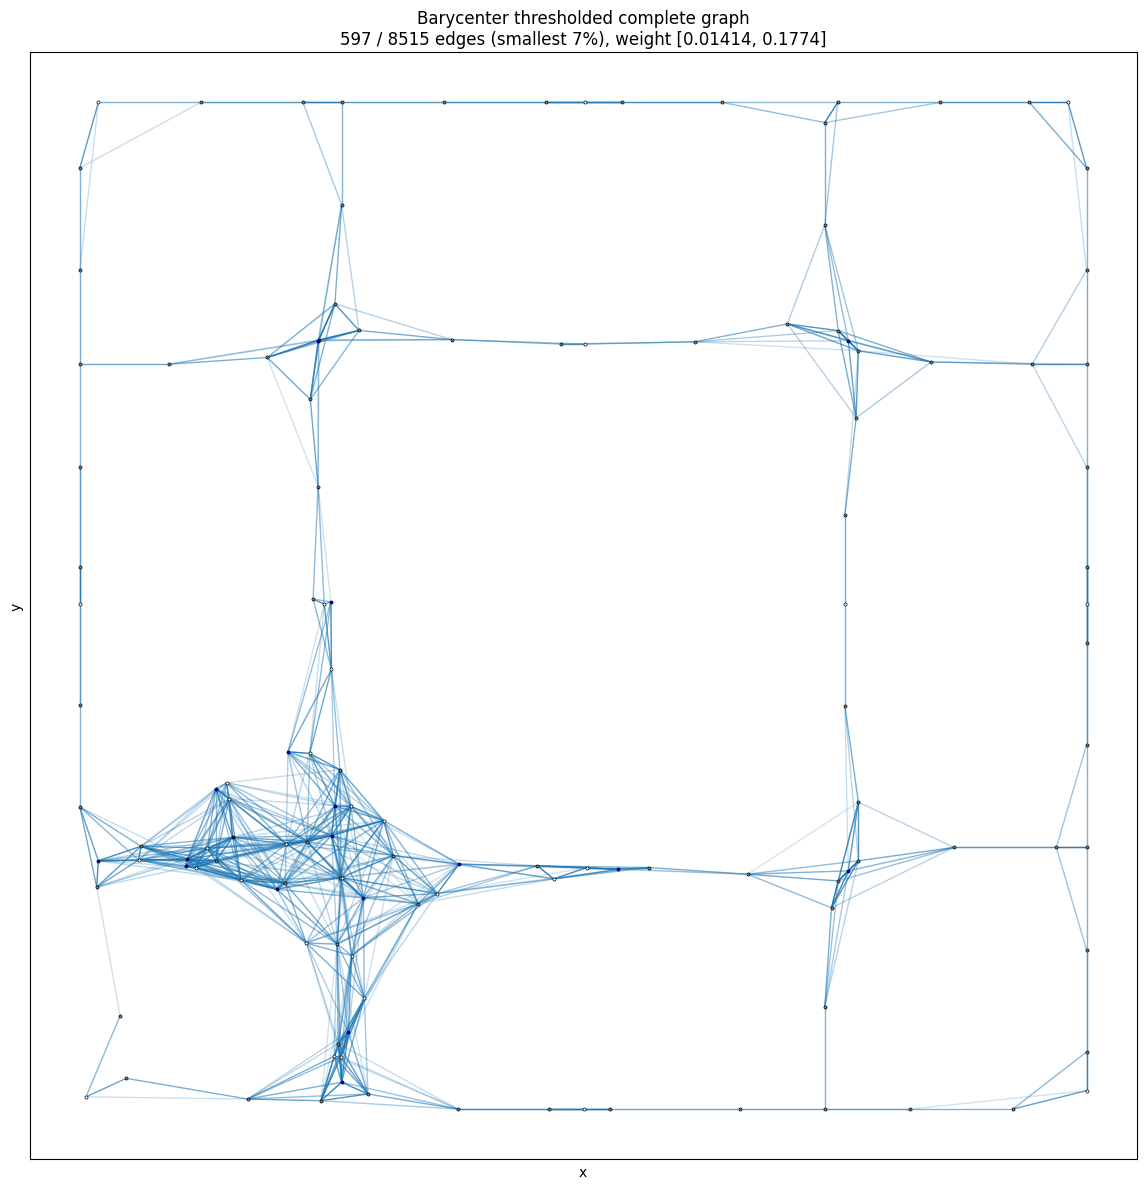

Kept 597 edges (7% of 8515 candidates); alpha in [0.2, 1.0] by weight


In [294]:
# Alternative barycenter view: fully connected graph, keep smallest-weight X% of edges
# (does not replace MST reconstruction above)

from lib.graph_reader import _inverse_relation_weight, draw_msc_nodes
from matplotlib.collections import LineCollection
import matplotlib.colors as mcolors


def barycenter_xy_positions(X_center, min_x, min_y, domain_size):
    """Same (x, y) layout as ``reconstruct_msc_barycenter_mst_graph``."""
    X = np.asarray(X_center, dtype=float)
    return {
        i: np.array(
            [min_x + X[i, 0] * domain_size, min_y + X[i, 1] * domain_size],
            dtype=float,
        )
        for i in range(X.shape[0])
    }


def set_barycenter_axes_limits(ax, pos, pad_frac=0.05):
    """Set xlim/ylim from node positions; y-axis span follows data (not forced square)."""
    xs = np.array([p[0] for p in pos.values()], dtype=float)
    ys = np.array([p[1] for p in pos.values()], dtype=float)
    xspan = float(xs.max() - xs.min())
    yspan = float(ys.max() - ys.min())
    xpad = xspan * pad_frac if xspan > 0 else 1.0
    ypad = yspan * pad_frac if yspan > 0 else 1.0
    ax.set_xlim(xs.min() - xpad, xs.max() + xpad)
    ax.set_ylim(ys.min() - ypad, ys.max() + ypad)
    ax.set_aspect("equal", adjustable="box")


def draw_barycenter_thresholded_complete(
    C_center,
    X_center,
    *,
    min_x,
    min_y,
    min_z,
    domain_size,
    relation_kind=relation_kind,
    relation_rescale=relation_rescale,
    relation_offset=relation_offset,
    edge_fraction_pct=10.0,
    alpha_min=0.2,
    alpha_max=1.0,
    edge_width=1.0,
    edge_color="#1f77b4",
    node_size=5,
    figsize=(16.0, 12.0),
    pos=None,
    pad_frac=0.05,
):
    """
    Visualize the FGW barycenter as a thresholded complete graph.

    - Collect all finite off-diagonal entries of ``C_center`` (unscaled).
    - Keep the ``edge_fraction_pct`` fraction with smallest weight (e.g. 10 => top 10%).
    - Edge alpha: lightest weight => ``alpha_max`` (opaque), heaviest kept => ``alpha_min``.
    """
    C = np.asarray(C_center, dtype=float)
    X = np.asarray(X_center, dtype=float)
    n = C.shape[0]

    if relation_kind == "shortestpath":
        C = np.nan_to_num(C, nan=np.inf, posinf=np.inf)
    else:
        C = np.nan_to_num(C, nan=0.0)

    candidates = []
    for i in range(n):
        for j in range(i + 1, n):
            w_scaled = C[i, j]
            if not np.isfinite(w_scaled) or w_scaled <= 0:
                continue
            w = _inverse_relation_weight(
                float(w_scaled),
                relation_kind=relation_kind,
                relation_rescale=relation_rescale,
                relation_offset=relation_offset,
            )
            candidates.append((w, i, j))

    if not candidates:
        print("No finite positive edges in C_center.")
        return

    candidates.sort(key=lambda e: e[0])
    k = max(1, int(np.ceil(len(candidates) * edge_fraction_pct / 100.0)))
    
    kept = candidates[:k]
    w_min, w_max = kept[0][0], kept[-1][0]

    def weight_to_alpha(w: float) -> float:
        if w_max <= w_min:
            return alpha_max
        t = (w - w_min) / (w_max - w_min)
        return float(alpha_max - t * (alpha_max - alpha_min))

    if pos is None:
        pos = barycenter_xy_positions(X, min_x, min_y, domain_size)

    fig, ax = plt.subplots(figsize=figsize)
    set_barycenter_axes_limits(ax, pos, pad_frac=pad_frac)

    segments = []
    alphas = []
    rgba_base = mcolors.to_rgba(edge_color)
    for w, u, v in kept:
        segments.append([pos[u], pos[v]])
        a = weight_to_alpha(w)
        alphas.append((rgba_base[0], rgba_base[1], rgba_base[2], a))

    if segments:
        lc = LineCollection(segments, colors=alphas, linewidths=edge_width)
        ax.add_collection(lc)

    G_nodes = nx.Graph()
    for n in pos:
        attrs = {}
        if "G_center" in globals() and G_center.has_node(n):
            attrs = dict(G_center.nodes[n])
        G_nodes.add_node(n, **attrs)
    draw_msc_nodes(G_nodes, pos, ax, regular_size=node_size, critical_size=node_size)

    ax.set_title(
        f"Barycenter thresholded complete graph\n"
        f"{len(kept)} / {len(candidates)} edges (smallest {edge_fraction_pct:g}%), "
        f"weight [{w_min:.4g}, {w_max:.4g}]"
    )
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    fig.tight_layout()
    plt.show()

    print(
        f"Kept {len(kept)} edges ({edge_fraction_pct:g}% of {len(candidates)} candidates); "
        f"alpha in [{alpha_min}, {alpha_max}] by weight"
    )


# --- tunables ---
EDGE_FRACTION_PCT = 7.0      # show smallest-weight X% of all pairs
ALPHA_MIN = 0.2              # most transparent (heaviest kept edge)
ALPHA_MAX = 1.0              # least transparent (lightest kept edge)

# Use G_center node coordinates when available so framing matches reconstruction exactly
_pos_recon = (
    {n: np.array([G_center.nodes[n]["x"], G_center.nodes[n]["y"]], dtype=float) for n in G_center.nodes()}
    if "G_center" in dir() and G_center.number_of_nodes() == X_center.shape[0]
    else None
)

draw_barycenter_thresholded_complete(
    C_center,
    X_center,
    min_x=min_x,
    min_y=min_y,
    min_z=min_z,
    domain_size=domain_size,
    relation_kind=relation_kind,
    relation_rescale=relation_rescale,
    relation_offset=relation_offset,
    edge_fraction_pct=EDGE_FRACTION_PCT,
    alpha_min=ALPHA_MIN,
    alpha_max=ALPHA_MAX,
    pos=_pos_recon,
)

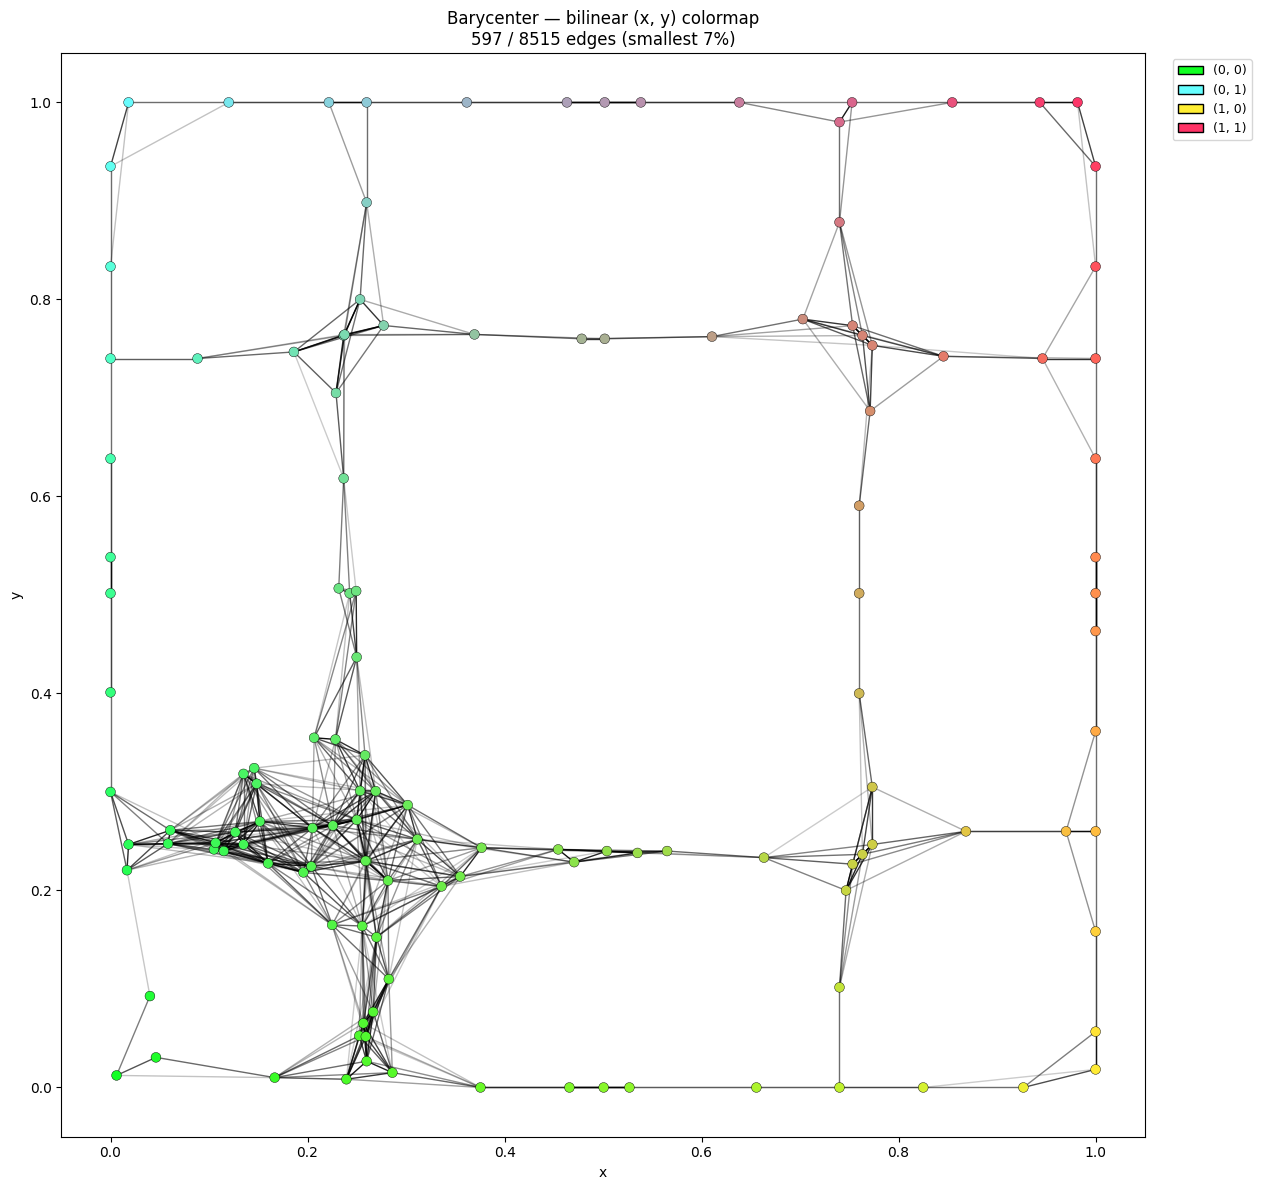

Colormap mode: bilinear; kept 597 edges (7% of 8515 candidates)


In [295]:
# Color transfer (1): barycenter colormap — bilinear (x, y) or categorical (node id)
# Uses the same thresholded-complete-graph layout as draw_barycenter_thresholded_complete.

from matplotlib.patches import Patch

# --- mode switch ---
# BARYCENTER_COLOR_MODE = "categorical"  # "bilinear" | "categorical"
BARYCENTER_COLOR_MODE = "bilinear"  # "bilinear" | "categorical"

# Bilinear corner colors (only used when BARYCENTER_COLOR_MODE == "bilinear")
BARYCENTER_CORNER_COLORS = ("#11FF22", "#66FFFF", "#FFEE33", "#FF3366")

# Categorical palette (only used when BARYCENTER_COLOR_MODE == "categorical")
BARYCENTER_CATEGORICAL_CMAP = "tab20"
BARYCENTER_CATEGORICAL_MAX_COLORS = 20


def bilinear_xy_rgba(x, y, min_x, max_x, min_y, max_y, corner_rgba):
    """
    Bilinear RGBA at world (x, y) from four corner colors:
      corner_rgba[0] at (min_x, min_y), [1] at (min_x, max_y),
      [2] at (max_x, min_y), [3] at (max_x, max_y).
    """
    dx = float(max_x - min_x)
    dy = float(max_y - min_y)
    u = 0.0 if dx <= 0 else float(np.clip((x - min_x) / dx, 0.0, 1.0))
    v = 0.0 if dy <= 0 else float(np.clip((y - min_y) / dy, 0.0, 1.0))
    c00, c01, c10, c11 = corner_rgba
    rgba = (
        (1.0 - u) * (1.0 - v) * np.asarray(c00, dtype=float)
        + u * (1.0 - v) * np.asarray(c10, dtype=float)
        + (1.0 - u) * v * np.asarray(c01, dtype=float)
        + u * v * np.asarray(c11, dtype=float)
    )
    return tuple(np.clip(rgba, 0.0, 1.0))


def barycenter_bilinear_node_colors(pos, min_x, max_x, min_y, max_y, corner_colors):
    """Return list of RGBA tuples for barycenter node indices 0..n-1."""
    corner_rgba = [mcolors.to_rgba(c) for c in corner_colors]
    colors = []
    for i in sorted(pos.keys()):
        x, y = pos[i]
        colors.append(bilinear_xy_rgba(x, y, min_x, max_x, min_y, max_y, corner_rgba))
    return colors


def barycenter_categorical_node_colors(n, *, max_colors=20, cmap="tab20"):
    """Assign up to ``max_colors`` distinct colors by barycenter node index (0..n-1)."""
    cmap_obj = plt.get_cmap(cmap)
    n_palette = min(int(max_colors), int(getattr(cmap_obj, "N", max_colors)))
    return [cmap_obj(i % n_palette) for i in range(int(n))]


def compute_barycenter_node_colors(
    mode,
    n,
    pos,
    *,
    min_x,
    max_x,
    min_y,
    max_y,
    corner_colors=BARYCENTER_CORNER_COLORS,
    categorical_cmap=BARYCENTER_CATEGORICAL_CMAP,
    categorical_max_colors=BARYCENTER_CATEGORICAL_MAX_COLORS,
):
    """Build per-node colors for the selected barycenter colormap mode."""
    if mode == "bilinear":
        return barycenter_bilinear_node_colors(pos, min_x, max_x, min_y, max_y, corner_colors)
    if mode == "categorical":
        return barycenter_categorical_node_colors(
            n, max_colors=categorical_max_colors, cmap=categorical_cmap
        )
    raise ValueError(f"Unknown BARYCENTER_COLOR_MODE={mode!r}. Use 'bilinear' or 'categorical'.")


def draw_barycenter_colormap(
    C_center,
    X_center,
    node_colors,
    *,
    color_mode="bilinear",
    min_x,
    min_y,
    max_x,
    max_y,
    min_z,
    domain_size,
    corner_colors=BARYCENTER_CORNER_COLORS,
    relation_kind=relation_kind,
    relation_rescale=relation_rescale,
    relation_offset=relation_offset,
    edge_fraction_pct=10.0,
    alpha_min=0.2,
    alpha_max=1.0,
    edge_width=1.0,
    edge_color="black",
    node_size=30,
    figsize=(16.0, 12.0),
    pos=None,
    pad_frac=0.05,
):
    """
    Thresholded-complete-graph barycenter view with custom per-node colors.
    ``color_mode`` controls title/legend only; colors are passed in ``node_colors``.
    """
    C = np.asarray(C_center, dtype=float)
    X = np.asarray(X_center, dtype=float)
    n = C.shape[0]

    if relation_kind == "shortestpath":
        C = np.nan_to_num(C, nan=np.inf, posinf=np.inf)
    else:
        C = np.nan_to_num(C, nan=0.0)

    candidates = []
    for i in range(n):
        for j in range(i + 1, n):
            w_scaled = C[i, j]
            if not np.isfinite(w_scaled) or w_scaled <= 0:
                continue
            w = _inverse_relation_weight(
                float(w_scaled),
                relation_kind=relation_kind,
                relation_rescale=relation_rescale,
                relation_offset=relation_offset,
            )
            candidates.append((w, i, j))

    if not candidates:
        print("No finite positive edges in C_center.")
        return None

    candidates.sort(key=lambda e: e[0])
    k = max(1, int(np.ceil(len(candidates) * edge_fraction_pct / 100.0)))
    kept = candidates[:k]
    w_min, w_max = kept[0][0], kept[-1][0]

    def weight_to_alpha(w: float) -> float:
        if w_max <= w_min:
            return alpha_max
        t = (w - w_min) / (w_max - w_min)
        return float(alpha_max - t * (alpha_max - alpha_min))

    if pos is None:
        pos = barycenter_xy_positions(X, min_x, min_y, domain_size)

    fig, ax = plt.subplots(figsize=figsize)
    set_barycenter_axes_limits(ax, pos, pad_frac=pad_frac)

    segments = []
    alphas = []
    rgba_base = mcolors.to_rgba(edge_color)
    for w, u, v in kept:
        segments.append([pos[u], pos[v]])
        a = weight_to_alpha(w)
        alphas.append((rgba_base[0], rgba_base[1], rgba_base[2], a))

    if segments:
        lc = LineCollection(segments, colors=alphas, linewidths=edge_width)
        ax.add_collection(lc)

    xs = [pos[i][0] for i in range(n)]
    ys = [pos[i][1] for i in range(n)]
    ax.scatter(
        xs,
        ys,
        s=node_size,
        c=node_colors,
        edgecolors="black",
        linewidths=0.3,
        zorder=3,
    )

    if color_mode == "bilinear":
        corner_labels = [
            f"({min_x:.3g}, {min_y:.3g})",
            f"({min_x:.3g}, {max_y:.3g})",
            f"({max_x:.3g}, {min_y:.3g})",
            f"({max_x:.3g}, {max_y:.3g})",
        ]
        legend_handles = [
            Patch(facecolor=corner_colors[i], edgecolor="black", label=corner_labels[i])
            for i in range(4)
        ]
        ax.legend(handles=legend_handles, loc="upper left", bbox_to_anchor=(1.02, 1.0), fontsize=9)
        mode_label = "bilinear (x, y) colormap"
    else:
        mode_label = (
            f"categorical colormap ({BARYCENTER_CATEGORICAL_CMAP}, "
            f"≤{BARYCENTER_CATEGORICAL_MAX_COLORS} colors by node id)"
        )

    ax.set_title(
        f"Barycenter — {mode_label}\n"
        f"{len(kept)} / {len(candidates)} edges (smallest {edge_fraction_pct:g}%)"
    )
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    fig.tight_layout(rect=[0, 0, 0.82, 1] if color_mode == "bilinear" else None)
    plt.show()

    print(
        f"Colormap mode: {color_mode}; "
        f"kept {len(kept)} edges ({edge_fraction_pct:g}% of {len(candidates)} candidates)"
    )
    return node_colors


_pos_recon_bilinear = (
    {n: np.array([G_center.nodes[n]["x"], G_center.nodes[n]["y"]], dtype=float) for n in G_center.nodes()}
    if "G_center" in dir() and G_center.number_of_nodes() == X_center.shape[0]
    else None
)

_pos_barycenter = _pos_recon_bilinear
if _pos_barycenter is None:
    _pos_barycenter = barycenter_xy_positions(X_center, min_x, min_y, domain_size)

barycenter_node_colors = compute_barycenter_node_colors(
    BARYCENTER_COLOR_MODE,
    X_center.shape[0],
    _pos_barycenter,
    min_x=min_x,
    max_x=max_x,
    min_y=min_y,
    max_y=max_y,
    corner_colors=BARYCENTER_CORNER_COLORS,
    categorical_cmap=BARYCENTER_CATEGORICAL_CMAP,
    categorical_max_colors=BARYCENTER_CATEGORICAL_MAX_COLORS,
)

barycenter_node_colors = draw_barycenter_colormap(
    C_center,
    X_center,
    barycenter_node_colors,
    color_mode=BARYCENTER_COLOR_MODE,
    min_x=min_x,
    min_y=min_y,
    max_x=max_x,
    max_y=max_y,
    min_z=min_z,
    domain_size=domain_size,
    corner_colors=BARYCENTER_CORNER_COLORS,
    relation_kind=relation_kind,
    relation_rescale=relation_rescale,
    relation_offset=relation_offset,
    edge_fraction_pct=EDGE_FRACTION_PCT,
    alpha_min=ALPHA_MIN,
    alpha_max=ALPHA_MAX,
    node_size=50,
    pos=_pos_barycenter,
)

# Backward-compatible alias for the color-transfer cell below
barycenter_bilinear_colors = barycenter_node_colors

Graph 0: coupling threshold = 7.95165e-05; pie nodes = 21 / 96
Graph 1: coupling threshold = 5.82717e-05; pie nodes = 0 / 131
Graph 2: coupling threshold = 5.82717e-05; pie nodes = 0 / 131


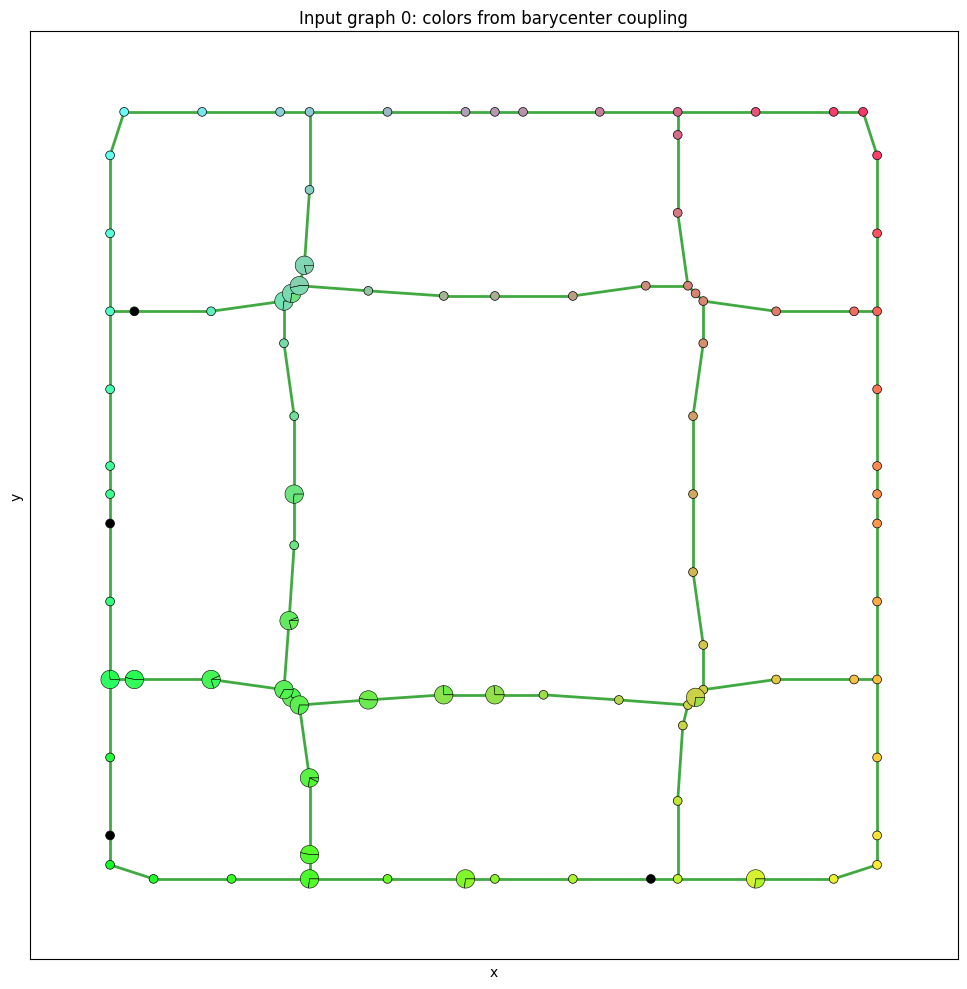

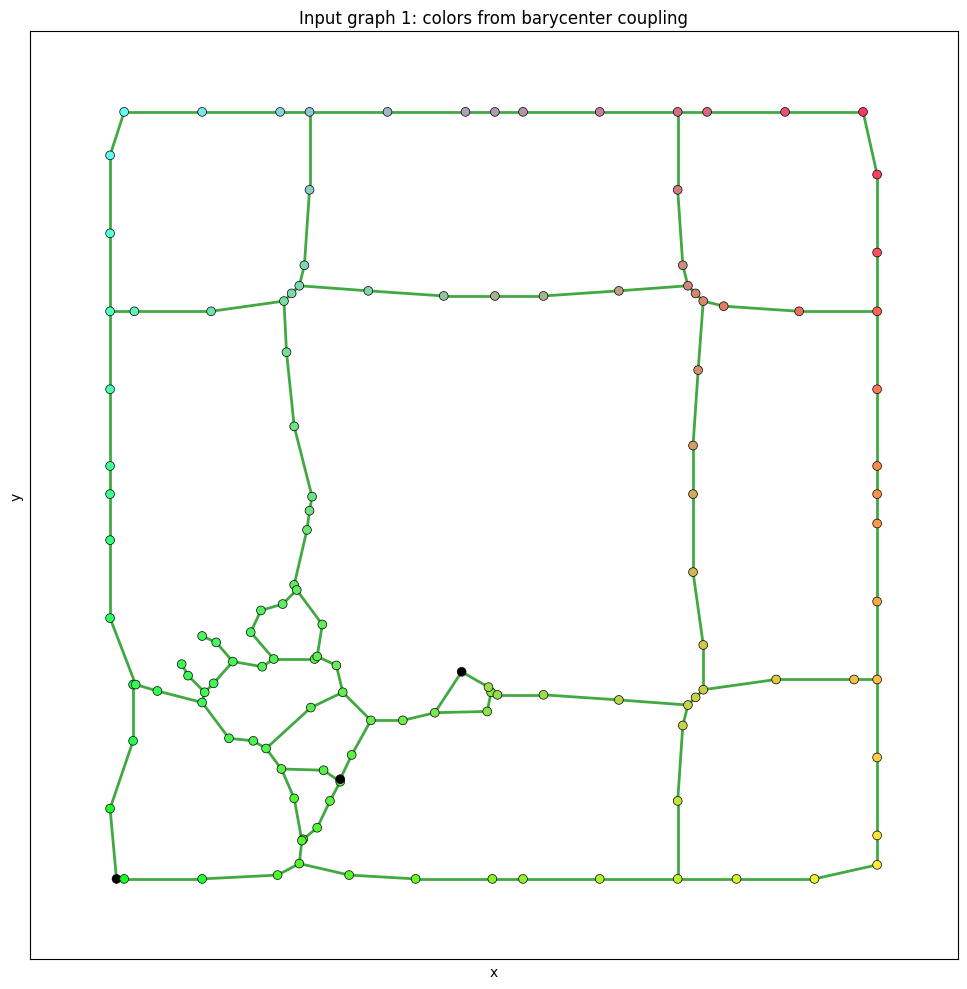

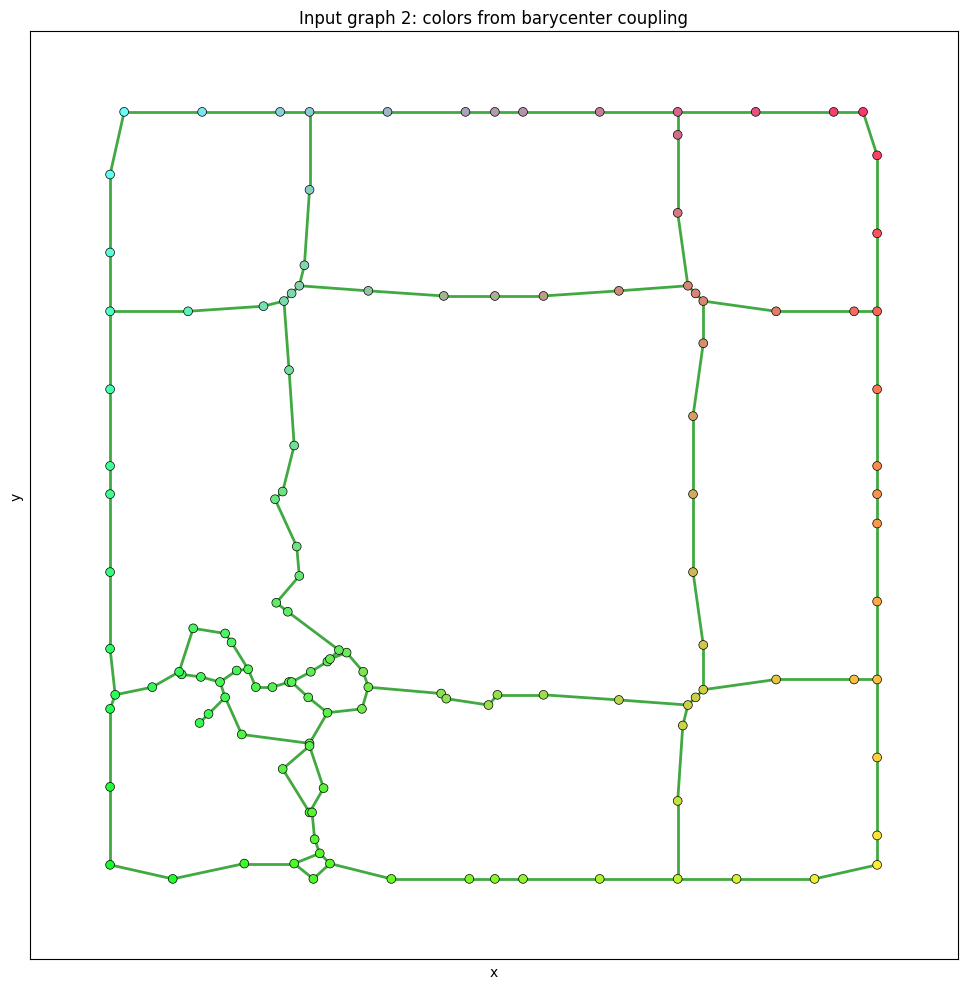

In [296]:
# Color transfer (2): map barycenter colors to each input graph via final PFGW couplings.
# Nodes coupled to multiple barycenter nodes (above threshold) are drawn as pie charts.

from matplotlib.patches import Wedge


def coupling_entry_threshold(T, p):
    """Ignore coupling entries below p.sum() / (n_bary * n_source)."""
    T = np.asarray(T, dtype=float)
    p = np.asarray(p, dtype=float)
    return float(p.sum()) / float(T.shape[0] * T.shape[1])


def transfer_barycenter_colors_to_inputs(
    Ts,
    barycenter_colors,
    p,
    *,
    mass_threshold=None,
):
    """
    Transfer barycenter node colors to each input graph using couplings Ts[s] (N_center, n_source).

    Returns per-graph lists of node colors (hex or list of (hex, frac) for pie charts)
    and use_pie flags aligned with nodes_list[s].
    """
    if barycenter_colors is None:
        raise ValueError("Run the barycenter colormap cell first.")

    p = np.asarray(p, dtype=float)
    bary_hex = [mcolors.to_hex(c) for c in barycenter_colors]
    all_node_colors = []
    all_use_pie = []

    for s, T in enumerate(Ts):
        T = np.asarray(T, dtype=float)
        thr = coupling_entry_threshold(T, p) if mass_threshold is None else float(mass_threshold)
        n_source = T.shape[1]
        node_colors = []
        use_pie = []

        for j in range(n_source):
            col = T[:, j]
            mask = col >= thr
            if not np.any(mask):
                node_colors.append("black")
                use_pie.append(False)
                continue

            idxs = np.where(mask)[0]
            weights = col[idxs]
            total = float(weights.sum())
            fracs = weights / total

            if len(idxs) == 1:
                node_colors.append(bary_hex[idxs[0]])
                use_pie.append(False)
            else:
                node_colors.append([(bary_hex[i], float(f)) for i, f in zip(idxs, fracs)])
                use_pie.append(True)

        all_node_colors.append(node_colors)
        all_use_pie.append(use_pie)
        print(f"Graph {s}: coupling threshold = {thr:.6g}; pie nodes = {sum(use_pie)} / {n_source}")

    return all_node_colors, all_use_pie


def _pie_radius_from_pos(pos, frac=0.012):
    xs = np.array([p[0] for p in pos.values()], dtype=float)
    ys = np.array([p[1] for p in pos.values()], dtype=float)
    span = max(float(xs.max() - xs.min()), float(ys.max() - ys.min()), 1e-9)
    return frac * span


def _draw_pie_at_xy(ax, center, color_fracs, radius):
    if not color_fracs:
        return
    total = sum(float(f) for _, f in color_fracs)
    if total <= 0:
        return
    start_deg = 0.0
    for color, frac in color_fracs:
        if frac <= 0:
            continue
        span_deg = 360.0 * float(frac) / total
        ax.add_patch(
            Wedge(
                center,
                radius,
                start_deg,
                start_deg + span_deg,
                facecolor=color,
                edgecolor="black",
                linewidth=0.4,
                zorder=4,
            )
        )
        start_deg += span_deg


def draw_input_graph_coupling_colors(
    G,
    nodes_order,
    node_colors,
    use_pie,
    *,
    mesh_id=None,
    figsize=(16.0, 10.0),
    edge_width=2.0,
    edge_color="#2ca02c",
    node_size=40,
    pie_radius=None,
):
    """Draw one input MSC graph with coupling-transferred node colors."""
    pos = msc_xy_positions(G)
    if pie_radius is None:
        pie_radius = _pie_radius_from_pos(pos)

    fig, ax = plt.subplots(figsize=figsize)
    nx.draw_networkx_edges(
        G,
        pos,
        edge_color=edge_color,
        width=edge_width,
        alpha=0.9,
        ax=ax,
    )

    node_to_idx = {n: i for i, n in enumerate(nodes_order)}
    xs, ys, colors = [], [], []
    for n in G.nodes():
        idx = node_to_idx.get(n, -1)
        if idx < 0:
            continue
        xy = pos[n]
        col = node_colors[idx]
        if use_pie[idx] and isinstance(col, list):
            _draw_pie_at_xy(ax, xy, col, pie_radius)
        else:
            c = col if isinstance(col, str) else "black"
            xs.append(xy[0])
            ys.append(xy[1])
            colors.append(c)

    if xs:
        ax.scatter(
            xs,
            ys,
            s=node_size,
            c=colors,
            edgecolors="black",
            linewidths=0.5,
            zorder=3,
        )

    title = (
        f"Input graph {mesh_id}: colors from barycenter coupling"
        if mesh_id is not None
        else "Input graph: colors from barycenter coupling"
    )
    ax.set_title(title)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_aspect("equal", adjustable="box")
    fig.tight_layout()
    plt.show()


if "barycenter_node_colors" not in dir() or barycenter_node_colors is None:
    _pos_tmp = _pos_barycenter if "_pos_barycenter" in dir() else (
        _pos_recon_bilinear if "_pos_recon_bilinear" in dir() else None
    )
    if _pos_tmp is None:
        _pos_tmp = barycenter_xy_positions(X_center, min_x, min_y, domain_size)
    _mode = BARYCENTER_COLOR_MODE if "BARYCENTER_COLOR_MODE" in dir() else "bilinear"
    barycenter_node_colors = compute_barycenter_node_colors(
        _mode,
        X_center.shape[0],
        _pos_tmp,
        min_x=min_x,
        max_x=max_x,
        min_y=min_y,
        max_y=max_y,
        corner_colors=BARYCENTER_CORNER_COLORS if "BARYCENTER_CORNER_COLORS" in dir() else ("#9933FF", "#66FFFF", "#FFEE33", "#FF3366"),
        categorical_cmap=BARYCENTER_CATEGORICAL_CMAP if "BARYCENTER_CATEGORICAL_CMAP" in dir() else "tab20",
        categorical_max_colors=BARYCENTER_CATEGORICAL_MAX_COLORS if "BARYCENTER_CATEGORICAL_MAX_COLORS" in dir() else 20,
    )

_p_bary = log["p"] if "p" in log else p
Ts_final = log["T"]

input_coupling_colors, input_use_pie = transfer_barycenter_colors_to_inputs(
    Ts_final,
    barycenter_node_colors,
    _p_bary,
)

for s, idx in enumerate(idx_list):
    draw_input_graph_coupling_colors(
        Gs[idx],
        nodes_list[s],
        input_coupling_colors[s],
        input_use_pie[s],
        mesh_id=mesh_ids[idx] if "mesh_ids" in dir() else idx,
    )